In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e5/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e5/train.csv
/kaggle/input/competitions/playground-series-s6e5/test.csv


In [2]:
df = pd.read_csv("/kaggle/input/competitions/playground-series-s6e5/train.csv")

In [3]:
df.head()

,id,Driver,Compound,Race,Year,PitStop,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap
0,0,D109,HARD,Canadian Grand Prix,2022,0,50,2,39.0,8,78.491,-7.564,21.019,0.714286,5.0,1.0
1,1,D086,HARD,Dutch Grand Prix,2025,1,27,2,7.0,4,75.095,-32.617,-223.207,0.346154,-3.0,0.0
2,2,ZON,HARD,Austrian Grand Prix,2022,0,59,3,22.0,13,70.945,-7.540,-100.529,0.819444,3.0,1.0
3,3,SPE,MEDIUM,Pre-Season Testing,2023,0,2,1,2.0,7,94.361,-7.324,-7.324,0.076923,0.0,0.0
4,4,D019,HARD,Azerbaijan Grand Prix,2022,1,26,3,6.0,2,107.878,8.965,-14.139,0.361111,3.0,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439140 entries, 0 to 439139
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      439140 non-null  int64  
 1   Driver                  439140 non-null  object 
 2   Compound                439140 non-null  object 
 3   Race                    439140 non-null  object 
 4   Year                    439140 non-null  int64  
 5   PitStop                 439140 non-null  int64  
 6   LapNumber               439140 non-null  int64  
 7   Stint                   439140 non-null  int64  
 8   TyreLife                439140 non-null  float64
 9   Position                439140 non-null  int64  
 10  LapTime (s)             439140 non-null  float64
 11  LapTime_Delta           439140 non-null  float64
 12  Cumulative_Degradation  439140 non-null  float64
 13  RaceProgress            439140 non-null  float64
 14  Position_Change     

No missing values in our column 

In [5]:
df.isnull().sum()

id                        0
Driver                    0
Compound                  0
Race                      0
Year                      0
PitStop                   0
LapNumber                 0
Stint                     0
TyreLife                  0
Position                  0
LapTime (s)               0
LapTime_Delta             0
Cumulative_Degradation    0
RaceProgress              0
Position_Change           0
PitNextLap                0
dtype: int64

In [6]:
df.describe()

,id,Year,PitStop,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap
count,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000
mean,219569.500000,2023.523544,0.136118,23.105909,1.789113,14.158231,9.630339,90.948735,-3.770040,-25.721759,0.337661,0.101542,0.198982
std,126768.942943,1.024930,0.342915,16.958261,0.950194,9.801338,5.278770,19.772769,43.945759,54.766573,0.253277,4.006765,0.399235
min,0.000000,2022.000000,0.000000,1.000000,1.000000,1.000000,1.000000,67.694000,-2403.895000,-274.564000,0.012821,-18.000000,0.000000
25%,109784.750000,2023.000000,0.000000,9.000000,1.000000,6.000000,5.000000,82.621000,-8.884000,-46.566250,0.129870,-1.000000,0.000000
50%,219569.500000,2024.000000,0.000000,19.000000,2.000000,12.000000,10.000000,90.521000,-0.295000,-20.994000,0.269231,0.000000,0.000000
75%,329354.250000,2024.000000,0.000000,36.000000,2.000000,20.000000,14.000000,98.471000,0.115000,-6.199000,0.513158,2.000000,0.000000
max,439139.000000,2025.000000,1.000000,78.000000,8.000000,77.000000,20.000000,2507.607000,2423.932000,2412.026000,1.000000,18.000000,1.000000


In [7]:
print(df["Driver"].value_counts())
print(df["Driver"].unique())
print("Number of values : " ,df["Driver"].nunique())

Driver
MAS     1682
RAI     1669
BAR     1656
BUT     1655
FIS     1651
        ... 
D723       1
D677       1
D731       1
D716       1
D714       1
Name: count, Length: 887, dtype: int64
['D109' 'D086' 'ZON' 'SPE' 'D019' 'D012' 'D104' 'D082' 'BEL' 'YAM' 'MAS'
 'D010' 'D063' 'D196' 'D132' 'D047' 'PRO' 'D066' 'DRA' 'PEA' 'HAD' 'HUL'
 'COU' 'D036' 'D205' 'BER' 'VIL' 'GUT' 'TUR' 'D089' 'D055' 'D189' 'D071'
 'DAM' 'D144' 'D384' 'D263' 'D117' 'D120' 'D054' 'D184' 'D214' 'IDE'
 'D216' 'D101' 'D160' 'WIL' 'CAR' 'D251' 'D106' 'D083' 'WAR' 'D065' 'MIN'
 'D293' 'BIA' 'D125' 'D073' 'ALE' 'D007' 'D009' 'D202' 'NOR' 'FRE' 'D057'
 'D177' 'D049' 'ALG' 'SUT' 'D312' 'D159' 'D219' 'ROS' 'D166' 'D218' 'D045'
 'D197' 'GIO' 'DIR' 'D138' 'WEB' 'D070' 'D097' 'LEC' 'D050' 'D369' 'HYD'
 'D355' 'D032' 'D292' 'BEA' 'D001' 'D232' 'D211' 'DIN' 'D157' 'NAK' 'TAY'
 'STR' 'D325' 'D028' 'RIC' 'ZHO' 'GAS' 'D041' 'D014' 'D283' 'WUR' 'D061'
 'D281' 'D046' 'TSU' 'D170' 'D122' 'D210' 'D191' 'D074' 'SHA' 'D128'
 'D254' 'D2

In [8]:
print(df["Compound"].value_counts())

Compound
MEDIUM          211141
HARD            170518
SOFT             38744
INTERMEDIATE     17382
WET               1355
Name: count, dtype: int64


In [9]:
print(df["Race"].unique())
print(df["Race"].value_counts())

['Canadian Grand Prix' 'Dutch Grand Prix' 'Austrian Grand Prix'
 'Pre-Season Testing' 'Azerbaijan Grand Prix' 'Saudi Arabian Grand Prix'
 'Belgian Grand Prix' 'United States Grand Prix' 'Italian Grand Prix'
 'Hungarian Grand Prix' 'Japanese Grand Prix' 'São Paulo Grand Prix'
 'Bahrain Grand Prix' 'Las Vegas Grand Prix' 'Monaco Grand Prix'
 'British Grand Prix' 'Australian Grand Prix' 'Spanish Grand Prix'
 'Miami Grand Prix' 'French Grand Prix' 'Abu Dhabi Grand Prix'
 'Chinese Grand Prix' 'Mexico City Grand Prix' 'Emilia Romagna Grand Prix'
 'Singapore Grand Prix' 'Qatar Grand Prix']
Race
Dutch Grand Prix             24462
Mexico City Grand Prix       23672
Pre-Season Testing           22492
Hungarian Grand Prix         22481
Monaco Grand Prix            21539
Canadian Grand Prix          21416
Austrian Grand Prix          21223
Spanish Grand Prix           20483
Italian Grand Prix           19854
Bahrain Grand Prix           19535
Singapore Grand Prix         18960
Miami Grand Prix    

In [10]:
print(df["Year"].value_counts())

Year
2023    136147
2024    127110
2025     92894
2022     82989
Name: count, dtype: int64


In [11]:
print("Average Lap Number :" ,df["LapNumber"].mean())
print("Maximum Lap Number :" ,df["LapNumber"].max())
print("Minimum Lap Number :" ,df["LapNumber"].min())

Average Lap Number : 23.105909277223663
Maximum Lap Number : 78
Minimum Lap Number : 1


In [12]:
print(df["Stint"].value_counts())


Stint
1    216288
2    129536
3     69238
4     18903
5      4281
6       728
7       116
8        50
Name: count, dtype: int64


In [13]:
print("Average tyrelife : ",df["TyreLife"].mean())
print("maximum tyrelife : ",df["TyreLife"].max())
print("Minimum tyrelife : ",df["TyreLife"].min())

Average tyrelife :  14.158230860317895
maximum tyrelife :  77.0
Minimum tyrelife :  1.0


In [14]:
print("unique positions:", df["Position"].nunique())

unique positions: 20


In [15]:
df["LapTime_Delta"].describe()

count    439140.000000
mean         -3.770040
std          43.945759
min       -2403.895000
25%          -8.884000
50%          -0.295000
75%           0.115000
max        2423.932000
Name: LapTime_Delta, dtype: float64

In [16]:
df["Cumulative_Degradation"].describe()

count    439140.000000
mean        -25.721759
std          54.766573
min        -274.564000
25%         -46.566250
50%         -20.994000
75%          -6.199000
max        2412.026000
Name: Cumulative_Degradation, dtype: float64

In [17]:
df["RaceProgress"].describe()

count    439140.000000
mean          0.337661
std           0.253277
min           0.012821
25%           0.129870
50%           0.269231
75%           0.513158
max           1.000000
Name: RaceProgress, dtype: float64

In [18]:
df["Position_Change"].describe()

count    439140.000000
mean          0.101542
std           4.006765
min         -18.000000
25%          -1.000000
50%           0.000000
75%           2.000000
max          18.000000
Name: Position_Change, dtype: float64

In [19]:
import matplotlib.pyplot as plt 
import seaborn as sns 

In [20]:
df["PitNextLap"].value_counts()

PitNextLap
0.0    351759
1.0     87381
Name: count, dtype: int64

<Axes: xlabel='PitNextLap'>

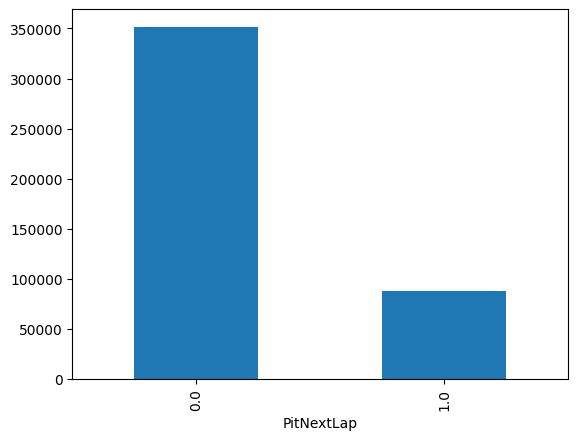

In [21]:
df["PitNextLap"].value_counts().plot(kind = "bar")

* Data set is imbalanced 

In [22]:
df.groupby("Driver")["PitNextLap"].value_counts()

Driver  PitNextLap
ALB     0.0            913
        1.0            433
ALE     0.0           1132
        1.0            319
ALG     0.0           1181
                      ... 
YAM     1.0            312
ZHO     0.0            822
        1.0            321
ZON     0.0           1130
        1.0            335
Name: count, Length: 1440, dtype: int64

In [23]:
df.groupby("Compound")["PitNextLap"].value_counts()

Compound      PitNextLap
HARD          0.0           114667
              1.0            55851
INTERMEDIATE  0.0            14735
              1.0             2647
MEDIUM        0.0           189788
              1.0            21353
SOFT          0.0            31248
              1.0             7496
WET           0.0             1321
              1.0               34
Name: count, dtype: int64

In [24]:
df.groupby("Year")["PitNextLap"].value_counts()

Year  PitNextLap
2022  0.0            60872
      1.0            22117
2023  0.0           134839
      1.0             1308
2024  0.0            89572
      1.0            37538
2025  0.0            66476
      1.0            26418
Name: count, dtype: int64

<Axes: >

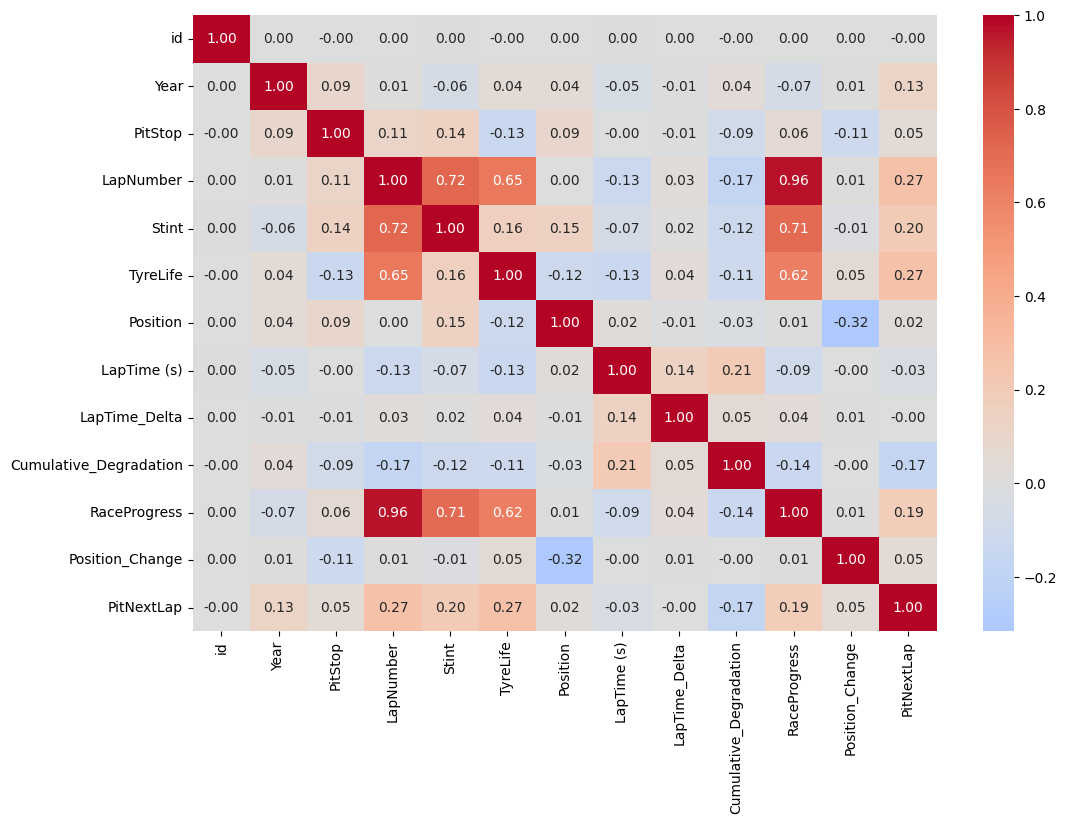

In [25]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0)

In [26]:
df.drop(columns=['RaceProgress'], inplace=True)

In [27]:
df.columns

Index(['id', 'Driver', 'Compound', 'Race', 'Year', 'PitStop', 'LapNumber',
       'Stint', 'TyreLife', 'Position', 'LapTime (s)', 'LapTime_Delta',
       'Cumulative_Degradation', 'Position_Change', 'PitNextLap'],
      dtype='object')

In [28]:
df['laps_since_pit'] = df.groupby(['Driver', 'Race'])['PitStop'].transform(
    lambda x: x.groupby(x.cumsum()).cumcount()
)

In [29]:
print(df[['TyreLife', 'laps_since_pit', 'Driver', 'Race']].head(20))

    TyreLife  laps_since_pit Driver                      Race
0       39.0               0   D109       Canadian Grand Prix
1        7.0               0   D086          Dutch Grand Prix
2       22.0               0    ZON       Austrian Grand Prix
3        2.0               0    SPE        Pre-Season Testing
4        6.0               0   D019     Azerbaijan Grand Prix
5       26.0               0   D012  Saudi Arabian Grand Prix
6       16.0               0   D104        Belgian Grand Prix
7        9.0               0   D082  United States Grand Prix
8        4.0               0    BEL        Italian Grand Prix
9        2.0               0    YAM      Hungarian Grand Prix
10      10.0               0    MAS       Japanese Grand Prix
11      12.0               0   D010      São Paulo Grand Prix
12       1.0               0   D063  Saudi Arabian Grand Prix
13      12.0               0   D012        Bahrain Grand Prix
14       5.0               0   D196        Italian Grand Prix
15      

In [30]:
from sklearn.preprocessing import OrdinalEncoder
compound_order = [['SOFT', 'MEDIUM', 'HARD', 'INTERMEDIATE', 'WET']]
ord_enc = OrdinalEncoder(categories = compound_order)
df["Compound"] = ord_enc.fit_transform(df[["Compound"]])

In [31]:
from sklearn.preprocessing import TargetEncoder
te_driver = TargetEncoder()
te_race   = TargetEncoder()

In [32]:
df['Driver'] = te_driver.fit_transform(df[['Driver']], df['PitNextLap'])
df['Race']   = te_race.fit_transform(df[['Race']],   df['PitNextLap'])

In [33]:
df = df.drop(columns = "PitStop")

In [34]:
X  = df.drop(columns = ["PitNextLap"], axis = 1)
y = df["PitNextLap"]

In [35]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.2 ,random_state = 42, stratify=y
                                                )

In [36]:
from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators = 500,
                   learning_rate = 0.05,
                   max_deapth = 6,
                   scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
                    random_state=42,
                    eval_metric='auc'
                    
                   )

In [37]:
xgb.fit(X_train,y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [05:01:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "max_deapth" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_deapth=6, max_delta_step=None,
              max_depth=None, max_leaves=None, min_child_weight=None,
              missing=nan, monotone_constraints=None, multi_strategy=None,
              n_estimators=500, n_jobs=None, ...)

In [38]:
y_pred_proba = xgb.predict_proba(X_test)[:, 1]
y_pred = xgb.predict(X_test)

In [39]:
from sklearn.metrics import roc_auc_score, classification_report
print("AUC Score:", roc_auc_score(y_test, y_pred_proba))
print(classification_report(y_test, y_pred))

AUC Score: 0.9453862877991991
              precision    recall  f1-score   support

         0.0       0.97      0.86      0.91     70352
         1.0       0.61      0.91      0.73     17476

    accuracy                           0.87     87828
   macro avg       0.79      0.88      0.82     87828
weighted avg       0.90      0.87      0.87     87828



In [40]:
df.head()

,id,Driver,Compound,Race,Year,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,Position_Change,PitNextLap,laps_since_pit
0,0,0.205657,2.0,0.153139,2022,50,2,39.0,8,78.491,-7.564,21.019,5.0,1.0,0
1,1,0.181254,2.0,0.174672,2025,27,2,7.0,4,75.095,-32.617,-223.207,-3.0,0.0,0
2,2,0.229632,2.0,0.186902,2022,59,3,22.0,13,70.945,-7.540,-100.529,3.0,1.0,0
3,3,0.196636,1.0,0.145497,2023,2,1,2.0,7,94.361,-7.324,-7.324,0.0,0.0,0
4,4,0.191811,2.0,0.213392,2022,26,3,6.0,2,107.878,8.965,-14.139,3.0,0.0,0


In [41]:
# Load test
test = pd.read_csv("/kaggle/input/competitions/playground-series-s6e5/test.csv")

# 1. Save IDs from sample submission
sample_sub = pd.read_csv("/kaggle/input/competitions/playground-series-s6e5/sample_submission.csv")
test_ids = sample_sub['id']

# 2. Drop same columns as train
test.drop(columns=['RaceProgress'], inplace=True)

# 3. Feature engineering
test['laps_since_pit'] = test.groupby(['Driver', 'Race'])['PitStop'].transform(
    lambda x: x.groupby(x.cumsum()).cumcount()
)

# 4. Encode — transform only
test["Compound"] = ord_enc.transform(test[["Compound"]])
test['Driver']   = te_driver.transform(test[['Driver']])
test["Race"]     = te_race.transform(test[["Race"]])

# 5. Drop PitStop
test = test.drop(columns=["PitStop"])

# 6. Match exact columns as train
test = test[X.columns]

# 7. Retrain on full data
xgb.fit(X, y)

# 8. Predict
predictions = xgb.predict_proba(test)[:, 1]

# 9. Final submission
submission = pd.DataFrame({
    'id': test_ids,
    'PitNextLap': predictions
})

submission.to_csv('submission.csv', index=False)
print(submission.head())
print("Shape:", submission.shape)
print(submission.isnull().sum())

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [05:02:08] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "max_deapth" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


       id  PitNextLap
0  439140    0.018350
1  439141    0.009552
2  439142    0.014127
3  439143    0.355371
4  439144    0.891453
Shape: (188165, 2)
id            0
PitNextLap    0
dtype: int64
